# State-Space Modeling

**State-space representation** keeps track of every internal variable
explicitly, through a set of first-order differential equations:

$$
\dot{\mathbf{x}} = A\mathbf{x} + B u, \qquad y = C\mathbf{x} + Du
$$

where $\mathbf{x}$ is the *state vector*. This page builds the state-space
model symbolically with SymPy, two different ways, and then uses it for
controllability, observability, and pole-placement design.

In [1]:
from IPython.core.display import HTML
from sympy import *
from mathprint import *

## 1. Transfer Function to State-Space

Given a strictly-proper transfer function

$$
G(s) = \frac{b_2 s^2 + b_1 s + b_0}{s^3 + a_2 s^2 + a_1 s + a_0}
$$

the **controllable canonical form** can be read directly off the
coefficients. Let's build $A$, $B$, $C$, $D$ symbolically for a general
third-order system, then substitute numbers at the end.


In [8]:
a0, a1, a2 = symbols('a0 a1 a2')
b0, b1, b2 = symbols('b0 b1 b2')

n = 3  # system order

A = zeros(n, n)
A[:-1, 1:] = eye(n - 1)
A[-1, :] = Matrix([[-a0, -a1, -a2]])

B = zeros(n, 1)
B[-1, 0] = 1

C = Matrix([[b0, b1, b2]])
D = Matrix([[0]])

mprint("A =", latex(A), ", B =", latex(B))
mprint("C =", latex(C), ", D =", latex(D))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

Sanity check: reconstruct $\boxed{G(s) = C(sI - A)^{-1}B + D}$ and confirm it
matches the transfer function we started from.


In [11]:
s = symbols('s')
I3 = eye(n)
G_reconstructed = simplify((C * (s * I3 - A).inv() * B + D)[0])
mprint("G(s)=", latex(G_reconstructed))


<IPython.core.display.Math object>

### Worked example

Take $G(s) = \dfrac{3s + 5}{s^3 + 6s^2 + 11s + 6}$ (poles at $-1, -2, -3$).


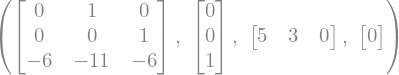

In [18]:
subs_numeric = {a0: 6, a1: 11, a2: 6, b0: 5, b1: 3, b2: 0}

A_n = A.subs(subs_numeric)
B_n = B.subs(subs_numeric)
C_n = C.subs(subs_numeric)
D_n = D.subs(subs_numeric)

A_n, B_n, C_n, D_n


## 2. ODEs to State-Space (Physical Derivation)

Canonical form is convenient but abstract — the states don't correspond to
anything physical. It's often more natural to derive $A$, $B$, $C$, $D$
directly from the governing ODEs, the way we did in *System Modeling:
Rectilinear System*.

Recall the mass-spring-damper system:

$$
m\ddot{x} + c\dot{x} + kx = F(t)
$$

Choose states $x_1 = x$ (position) and $x_2 = \dot{x}$ (velocity). Then:

$$
\dot{x}_1 = x_2, \qquad \dot{x}_2 = \frac{1}{m}\left(F - c x_2 - k x_1\right)
$$


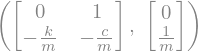

In [19]:
m, c, k, F = sp.symbols('m c k F')
x1, x2 = sp.symbols('x1 x2')

x1_dot = x2
x2_dot = (F - c * x2 - k * x1) / m

A_phys = sp.Matrix([[sp.diff(x1_dot, x1), sp.diff(x1_dot, x2)],
                     [sp.diff(x2_dot, x1), sp.diff(x2_dot, x2)]])

B_phys = sp.Matrix([[sp.diff(x1_dot, F)],
                     [sp.diff(x2_dot, F)]])

A_phys, B_phys


Output is position, so $C = \begin{bmatrix}1 & 0\end{bmatrix}$,
$D = 0$. Note $A_{\text{phys}}$ has exactly the same structure as the
canonical form above once we set $a_0 = k/m$, $a_1 = c/m$ — same physics,
different (equally valid) coordinate choice.


In [20]:
C_phys = sp.Matrix([[1, 0]])
D_phys = sp.Matrix([[0]])
C_phys, D_phys


## 3. Solving the State Equation Symbolically

The free (zero-input) response is $\mathbf{x}(t) = e^{At}\mathbf{x}(0)$.
SymPy computes the matrix exponential directly for small, numeric $A$.


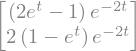

In [26]:
t = sp.symbols('t', positive=True)

A_num = sp.Matrix([[0, 1], [-2, -3]])   # poles at -1, -2
x0 = sp.Matrix([[1], [0]])

x_t = sp.simplify((A_num * t).exp() * x0)
x_t


Compare this against the step/impulse response obtained from the
equivalent transfer function on the *Second-Order System* page — both
routes must agree, since they describe the same physical system in
different coordinates.


## 4. Controllability

A system is controllable if the controllability matrix

$$
\mathcal{C} = \begin{bmatrix} B & AB & A^2B & \cdots & A^{n-1}B \end{bmatrix}
$$

has full rank $n$. Let's write a small symbolic helper and test it on a
controllable system, then on a deliberately uncontrollable one.


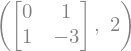

In [27]:
def controllability_matrix(A, B):
    n = A.shape[0]
    cols = [B]
    for i in range(1, n):
        cols.append(A**i * B)
    return sp.Matrix.hstack(*cols)

# Controllable example
A_c = sp.Matrix([[0, 1], [-2, -3]])
B_c = sp.Matrix([[0], [1]])

Cc = controllability_matrix(A_c, B_c)
Cc, Cc.rank()


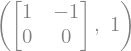

In [28]:
# Deliberately uncontrollable example:
# input only drives x1, and x1, x2 are decoupled
A_uc = sp.Matrix([[-1, 0], [0, -2]])
B_uc = sp.Matrix([[1], [0]])

Cuc = controllability_matrix(A_uc, B_uc)
Cuc, Cuc.rank()


The rank drops to 1 — $u$ can never influence $x_2$, since $B$ has
no component in that direction and $A$ is diagonal (decoupled). This is
exactly what "uncontrollable" looks like algebraically.


## 5. Observability

The dual notion: a system is observable if

$$
\mathcal{O} = \begin{bmatrix} C \\ CA \\ CA^2 \\ \vdots \\ CA^{n-1} \end{bmatrix}
$$

has full rank $n$.


In [32]:
def observability_matrix(A, C):
    n = A.shape[0]
    rows = [C]
    for i in range(1, n):
        rows.append(C * A**i)
    return sp.Matrix.vstack(*rows) 


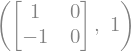

In [33]:
# Deliberately unobservable example: output only sees x1,
# and x2 doesn't affect x1's dynamics
A_uo = sp.Matrix([[-1, 0], [0, -2]])
C_uo = sp.Matrix([[1, 0]])

Ouo = observability_matrix(A_uo, C_uo)
Ouo, Ouo.rank()


Same story as before, mirrored: $x_2$ never shows up in $y$, and
since the system is decoupled, its motion is invisible from the output.


## 6. Pole Placement (State Feedback)

With full-state feedback $u = -K\mathbf{x}$, the closed-loop dynamics
become $\dot{\mathbf{x}} = (A - BK)\mathbf{x}$. We choose $K$ so that
$A - BK$ has a desired characteristic polynomial — i.e. desired closed-loop
poles.

**Ackermann's formula** gives $K$ directly, purely symbolically:

$$
K = \begin{bmatrix}0 & \cdots & 0 & 1\end{bmatrix} \mathcal{C}^{-1} \; \phi_d(A)
$$

where $\phi_d(A)$ is the desired characteristic polynomial evaluated at the
matrix $A$, and $\mathcal{C}$ is the controllability matrix (which must be
invertible — i.e. the system must be controllable, tying directly back to
Section 4).


In [34]:
def ackermann(A, B, desired_poles):
    n = A.shape[0]
    s = sp.symbols('s')

    # Desired characteristic polynomial phi_d(s)
    phi_d = sp.prod([(s - p) for p in desired_poles])
    phi_d = sp.expand(phi_d)
    phi_d_poly = sp.Poly(phi_d, s)

    # phi_d(A) via Cayley-Hamilton-style substitution
    coeffs = phi_d_poly.all_coeffs()  # highest degree first
    phi_d_A = sp.zeros(n, n)
    deg = len(coeffs) - 1
    for i, c in enumerate(coeffs):
        power = deg - i
        phi_d_A += c * A**power

    Cmat = controllability_matrix(A, B)
    e_n = sp.zeros(1, n)
    e_n[0, -1] = 1

    K = e_n * Cmat.inv() * phi_d_A
    return sp.simplify(K)

# Plant: A_c, B_c from Section 4 (poles currently at -1, -2)
desired_poles = [-4, -6]
K = ackermann(A_c, B_c, desired_poles)
K


Verify: the eigenvalues of $A - BK$ should now match the desired
poles exactly.


In [35]:
A_cl = A_c - B_c * K
sp.simplify(A_cl.eigenvals())


This closed-loop design step is exactly what *PID-Control (with
Derivative Filter) in State-Space Format* uses when it selects PID gains
for a desired transient response — Ackermann's formula is the general
version of that gain-selection problem.

## What's next

A Luenberger observer is the exact dual of Section 6 — placing the
eigenvalues of $A - LC$ using the same `ackermann()` routine applied to
$(A^T, C^T)$ instead of $(A, B)$. That's a natural follow-up page once this
one is in the book.
